# Aprendizaje por Refuerzo: Aterrizaje en la Luna con PPO (Lunar Lander)

**Autor:** Arturo Vargas Espinosa

En este reporte vamos a entrenar a un agente para que aprenda a **aterrizar una nave en la luna** con el ambiente `LunarLander-v3` de Gymnasium. La nave tiene que aterrizar entre las dos banderas amarillas usando sus motores, sin estrellarse.

El ambiente le da al agente **8 variables** (posición, velocidad, ángulo, velocidad angular y si cada pata toca el suelo) y tiene **4 acciones**: no hacer nada, motor izquierdo, motor principal y motor derecho. La recompensa sube si se acerca a la plataforma despacio y derecho, baja si gasta combustible, y al final da **−100 si se estrella** o **+100 si aterriza**. Un episodio se considera exitoso con **200 puntos o más**.

Las variables son continuas y son muchas para partirlas en rangos y usar una tabla como en Q-learning, así que usamos **PPO** de `stable-baselines3`, que en vez de tabla usa una red neuronal que da la probabilidad de cada acción y la va ajustando para que las acciones que dieron más recompensa sean más probables.

Vamos a entrenar **por partes**: entrenamos un rato, hacemos un gif de unos 8 segundos de lo que ya sabe hacer el agente, comentamos qué se ve, y seguimos entrenando.

### 1. Instalación de dependencias
Instalamos `gymnasium` con Box2D (la física de Lunar Lander) y `stable-baselines3` para PPO. Con `render_mode='rgb_array'` el ambiente regresa cada imagen como un arreglo, así que no hace falta abrir ninguna ventana.

In [1]:
%pip install -q "gymnasium[box2d]" stable-baselines3

Note: you may need to restart the kernel to use updated packages.


### 2. Definir e inicializar el ambiente
Creamos el ambiente `LunarLander-v3` con `render_mode='rgb_array'` para poder sacar las imágenes, y vemos la observación y los espacios de acciones y observaciones. Usamos la semilla 67 para que siempre empiece igual.

In [2]:
import os
os.environ['PYGAME_HIDE_SUPPORT_PROMPT'] = '1'   # para que pygame no imprima su mensaje
import warnings
import base64
import io
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import gymnasium as gym
from PIL import Image
from IPython.display import HTML
%matplotlib inline
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

SEMILLA = 67

# Crear el ambiente
env = gym.make('LunarLander-v3', render_mode='rgb_array')

# Inicializar el ambiente
observation, info = env.reset(seed=SEMILLA)

# Imprimir detalles del espacio de estados y acciones
print("Observación inicial:", observation.round(3))
print("Shape de la observación:", observation.shape)
print("Espacio de acciones (action_space):", env.action_space)
print("Espacio de observaciones (observation_space):", env.observation_space)

Observación inicial: [ 0.005  1.419  0.513  0.353 -0.006 -0.116  0.     0.   ]
Shape de la observación: (8,)
Espacio de acciones (action_space): Discrete(4)
Espacio de observaciones (observation_space): Box([ -2.5        -2.5       -10.        -10.         -6.2831855 -10.
  -0.         -0.       ], [ 2.5        2.5       10.        10.         6.2831855 10.
  1.         1.       ], (8,), float32)


Aquí podemos ver que la observación tiene 8 números: la nave empieza casi en el centro ($x \approx 0$) y arriba ($y \approx 1.4$), con las patas en 0 porque no toca el suelo. Hay 4 acciones posibles (`Discrete(4)`).

### 3. Mostrar frame inicial
Renderizamos el primer frame y lo mostramos con `matplotlib`.

Tamaño de la imagen: (400, 600, 3)


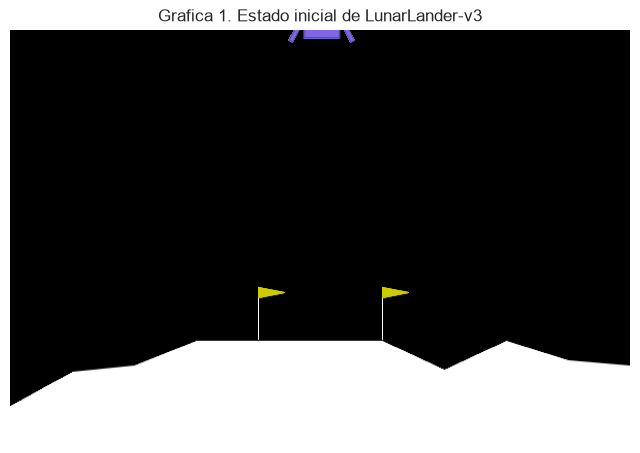

In [3]:
# Renderizar la pantalla
frame = env.render()
print("Tamaño de la imagen:", frame.shape)

# Mostrar la imagen
plt.figure(figsize=(8, 5.5))
plt.imshow(frame)
plt.axis('off')
plt.title("Grafica 1. Estado inicial de LunarLander-v3")
plt.show()

La plataforma es la parte plana entre las banderas; el terreno de los lados cambia en cada episodio.

### 4. Acciones manuales
Un solo paso casi no se nota, así que hacemos 30 pasos con la acción 0 (no hacer nada) y 30 con la acción 2 (motor principal), empezando las dos veces desde el mismo estado.

Acción 0 (no hacer nada): recompensa del último paso = -1.353, terminated = False, truncated = False
Acción 2 (motor principal): recompensa del último paso = -2.422, terminated = False, truncated = False


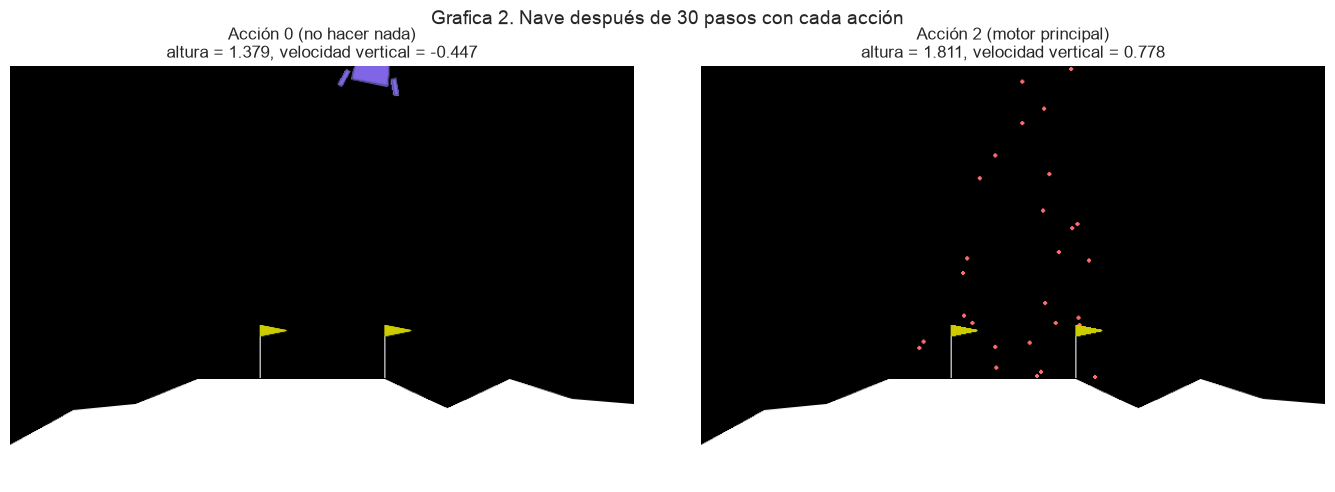

In [4]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 5))

for ax, accion, nombre in zip(ejes, [0, 2], ['Acción 0 (no hacer nada)', 'Acción 2 (motor principal)']):
    observation, info = env.reset(seed=SEMILLA)
    for paso in range(30):
        observation, reward, terminated, truncated, info = env.step(accion)

    ax.imshow(env.render())
    ax.axis('off')
    ax.set_title(f"{nombre}\naltura = {observation[1]:.3f}, velocidad vertical = {observation[3]:.3f}")
    print(f"{nombre}: recompensa del último paso = {reward:.3f}, terminated = {terminated}, truncated = {truncated}")

fig.suptitle("Grafica 2. Nave después de 30 pasos con cada acción", fontsize=14)
plt.tight_layout()
plt.show()

Aquí podemos ver que sin hacer nada la nave va cayendo, y con el motor principal sube tanto que se sale de la pantalla (solo se ven las partículas del motor). O sea que para aterrizar hay que prender y apagar el motor en el momento justo.

### 5. Agente aleatorio
Jugamos 4 episodios con acciones al azar y hacemos un gif con las imágenes, para ver cómo se ve un agente que no sabe nada. El gif se muestra con HTML y Base64.

Episodio aleatorio 1: recompensa = -166.2, pasos = 129
Episodio aleatorio 2: recompensa = -372.2, pasos = 95


Episodio aleatorio 3: recompensa = -405.7, pasos = 89
Episodio aleatorio 4: recompensa = -87.4, pasos = 66



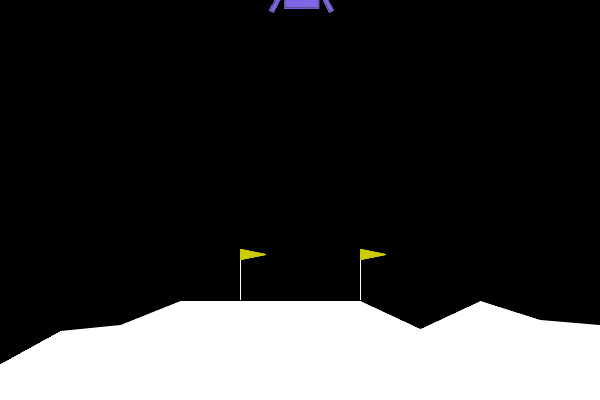

In [5]:
#Codigo hecho con claude
def a_cuadro(frame):
    # Pasa la imagen del ambiente a 32 colores para que el gif pese poco
    return Image.fromarray(frame).convert('P', palette=Image.Palette.ADAPTIVE, colors=32)

def mostrar_gif(cuadros, segundos=7):
    # Hace un gif de unos 8 segundos (si los cuadros dan para más, se acelera)
    maximo = segundos * 25
    if len(cuadros) > maximo:
        indices = np.linspace(0, len(cuadros) - 1, maximo).astype(int)
        cuadros = [cuadros[i] for i in indices]
    cuadros = cuadros + [cuadros[-1]] * 25   # 1 segundo quieto al final para ver cómo terminó
    buffer = io.BytesIO()
    cuadros[0].save(buffer, format='GIF', save_all=True, append_images=cuadros[1:], duration=40, loop=0)
    gif_codificado = base64.b64encode(buffer.getvalue()).decode('utf-8')
    return HTML(f'<img src="data:image/gif;base64,{gif_codificado}" width="600">')

env.action_space.seed(SEMILLA)
frames = []

for episodio in range(4):
    observation, info = env.reset(seed=SEMILLA + episodio)
    frames.append(a_cuadro(env.render()))
    total_reward, pasos, done = 0.0, 0, False

    while not done:
        # Seleccionar acción aleatoria del espacio de acciones
        action = env.action_space.sample()
        observation, reward, terminated, truncated, info = env.step(action)
        total_reward += reward
        pasos += 1
        done = terminated or truncated
        if pasos % 2 == 0 or done:   # con 1 de cada 2 imágenes el gif va a velocidad normal
            frames.append(a_cuadro(env.render()))

    print(f"Episodio aleatorio {episodio + 1}: recompensa = {total_reward:.1f}, pasos = {pasos}")

mostrar_gif(frames)

Aquí podemos ver que el agente aleatorio prende los motores sin ningún sentido: la nave gira, se va para los lados y se estrella lejos de las banderas, y hasta se llega a salir de la pantalla. Los episodios duran de 66 a 129 pasos (menos de 3 segundos) y la recompensa es muy negativa.

### 6. Simulación de 1,000 episodios aleatorios e histograma
Jugamos 1,000 episodios al azar para tener la línea base contra la que vamos a comparar al agente entrenado.

In [6]:
env_rapido = gym.make('LunarLander-v3')
env_rapido.action_space.seed(SEMILLA)
num_episodes = 1000
recompensas_aleatorias = []

for episode in range(num_episodes):
    observation, info = env_rapido.reset(seed=SEMILLA + episode)
    done = False
    total_reward = 0.0

    while not done:
        action = env_rapido.action_space.sample()
        observation, reward, terminated, truncated, info = env_rapido.step(action)
        total_reward += reward
        done = terminated or truncated

    recompensas_aleatorias.append(total_reward)

env_rapido.close()
recompensas_aleatorias = np.array(recompensas_aleatorias)

print(f"Simulación de {num_episodes} episodios completada.")
print(f"Recompensa promedio: {recompensas_aleatorias.mean():.2f}")
print(f"Recompensa máxima: {recompensas_aleatorias.max():.2f}")
print(f"Recompensa mínima: {recompensas_aleatorias.min():.2f}")
print(f"Episodios exitosos (200 puntos o más): {(recompensas_aleatorias >= 200).sum()}")

Simulación de 1000 episodios completada.
Recompensa promedio: -181.24
Recompensa máxima: 50.97
Recompensa mínima: -586.96
Episodios exitosos (200 puntos o más): 0


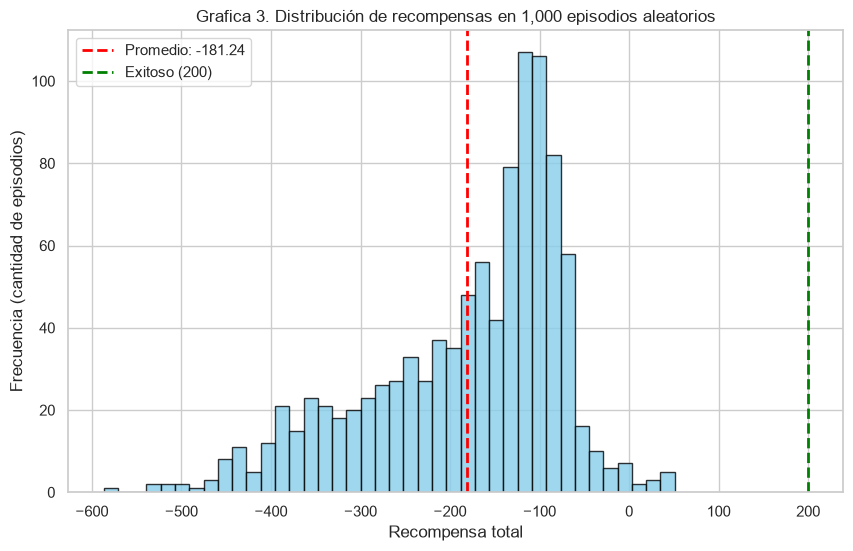

In [7]:
plt.figure(figsize=(10, 6))
plt.hist(recompensas_aleatorias, bins=40, color='skyblue', edgecolor='black', alpha=0.8)
plt.axvline(recompensas_aleatorias.mean(), color='red', linestyle='dashed', linewidth=2,
            label=f'Promedio: {recompensas_aleatorias.mean():.2f}')
plt.axvline(200, color='green', linestyle='dashed', linewidth=2, label='Exitoso (200)')
plt.title("Grafica 3. Distribución de recompensas en 1,000 episodios aleatorios")
plt.xlabel("Recompensa total")
plt.ylabel("Frecuencia (cantidad de episodios)")
plt.legend()
plt.show()

Aquí podemos ver que casi todos los episodios aleatorios quedan muy por debajo de 0 (promedio de −181) y ninguno llega a 200.

### 7. Guardar episodios durante el entrenamiento
Para poder ver qué va haciendo el agente conforme aprende, hacemos un *wrapper* que se pone encima del ambiente: numera cada episodio del entrenamiento, anota la recompensa y los pasos de todos, y guarda las imágenes de los episodios que vamos a ver más abajo.

In [8]:
#Codigo hecho con claude
registro = {'contador': 0, 'historial': []}
guardados = {}
episodios_a_guardar = {1, 2, 3, 5, 500, 525, 550, 575, 1000, 1025, 1050, 1075,
                       1400, 1425, 1450, 1950, 2300, 2575, 2825}

class GuardarEpisodios(gym.Wrapper):
    def reset(self, **kwargs):
        obs, info = self.env.reset(**kwargs)
        registro['contador'] += 1                 # número del episodio que empieza
        self.episodio = registro['contador']
        self.recompensas = []
        self.guardando = self.episodio in episodios_a_guardar
        self.cuadros = [a_cuadro(self.env.render())] if self.guardando else []
        return obs, info

    def step(self, accion):
        obs, recompensa, terminated, truncated, info = self.env.step(accion)
        self.recompensas.append(float(recompensa))
        termino = terminated or truncated
        if self.guardando and (len(self.recompensas) % 2 == 0 or termino):
            self.cuadros.append(a_cuadro(self.env.render()))
        if termino:
            total = sum(self.recompensas)
            registro['historial'].append({'episodio': self.episodio, 'recompensa': total, 'pasos': len(self.recompensas)})
            if self.guardando:
                guardados[self.episodio] = {'cuadros': self.cuadros, 'recompensa': total, 'pasos': len(self.recompensas)}
        return obs, recompensa, terminated, truncated, info

### 8. Crear los ambientes y el modelo PPO
Creamos 16 copias del ambiente en paralelo (para que entrene más rápido) y el modelo PPO. Los hiperparámetros son los que recomienda RL Zoo para Lunar Lander; `gamma=0.999` hace que le importe mucho la recompensa del final (el +100 de aterrizar).

In [9]:
#Codigo hecho con claude
from stable_baselines3 import PPO
from stable_baselines3.common.env_util import make_vec_env

envs = make_vec_env('LunarLander-v3', n_envs=16, seed=SEMILLA,
                    env_kwargs={'render_mode': 'rgb_array'},
                    wrapper_class=GuardarEpisodios)

modelo = PPO('MlpPolicy', envs,
             n_steps=1024, batch_size=64, n_epochs=4,
             gamma=0.999, gae_lambda=0.98, ent_coef=0.01,
             seed=SEMILLA, device='cpu', verbose=0)

print(modelo.policy)

ActorCriticPolicy(
  (features_extractor): FlattenExtractor(
    (flatten): Flatten(start_dim=1, end_dim=-1)
  )
  (pi_features_extractor): FlattenExtractor(
    (flatten): Flatten(start_dim=1, end_dim=-1)
  )
  (vf_features_extractor): FlattenExtractor(
    (flatten): Flatten(start_dim=1, end_dim=-1)
  )
  (mlp_extractor): MlpExtractor(
    (policy_net): Sequential(
      (0): Linear(in_features=8, out_features=64, bias=True)
      (1): Tanh()
      (2): Linear(in_features=64, out_features=64, bias=True)
      (3): Tanh()
    )
    (value_net): Sequential(
      (0): Linear(in_features=8, out_features=64, bias=True)
      (1): Tanh()
      (2): Linear(in_features=64, out_features=64, bias=True)
      (3): Tanh()
    )
  )
  (action_net): Linear(in_features=64, out_features=4, bias=True)
  (value_net): Linear(in_features=64, out_features=1, bias=True)
)


### 9. Entrenar por partes
Cada actualización de PPO usa 16 × 1,024 = 16,384 pasos. La función `entrenar_hasta()` entrena de actualización en actualización hasta que ya terminaron los episodios que queremos ver, y `ver_episodios()` imprime cómo les fue y hace su gif. Así, cada sección de abajo sigue el entrenamiento desde donde se quedó.

In [10]:
#Codigo hecho con claude
PASOS_POR_ACTUALIZACION = 16 * 1024
tiempo_entrenando = 0.0

def entrenar_hasta(episodios):
    global tiempo_entrenando
    inicio = time.time()
    while not all(e in guardados for e in episodios):
        modelo.learn(PASOS_POR_ACTUALIZACION, reset_num_timesteps=False)
    tiempo_entrenando += time.time() - inicio
    print(f"Pasos de entrenamiento hasta ahora: {modelo.num_timesteps:,}")

def ver_episodios(episodios):
    cuadros = []
    for e in episodios:
        print(f"Episodio {e:,}: recompensa = {guardados[e]['recompensa']:.1f}, pasos = {guardados[e]['pasos']}")
        cuadros += guardados[e]['cuadros']
    return mostrar_gif(cuadros)

### 10. Episodios 1, 2, 3 y 5
Empezamos el entrenamiento y vemos los primeros episodios. Cada uno dura como 2 segundos, así que el gif junta 4 para llegar a los 8 segundos.

Pasos de entrenamiento hasta ahora: 16,384
Episodio 1: recompensa = -331.9, pasos = 107
Episodio 2: recompensa = -131.8, pasos = 92
Episodio 3: recompensa = -281.2, pasos = 96
Episodio 5: recompensa = -85.4, pasos = 108



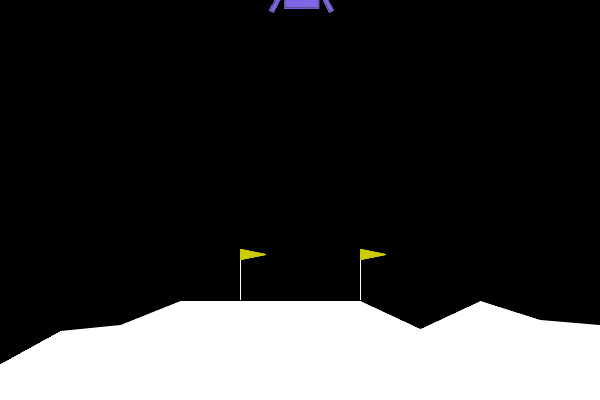

In [11]:
#Codigo hecho con claude
episodios = [1, 2, 3, 5]
entrenar_hasta(episodios)
ver_episodios(episodios)

Aquí podemos ver que al principio el agente no sabe nada y se ve igual que el agente aleatorio: la nave gira, se va para los lados y se estrella fuera de la plataforma, y en el episodio 3 hasta se sale de la pantalla. La recompensa va de −85 a −332.

### 11. Episodios 500, 525, 550 y 575
Seguimos entrenando hasta los episodios 500 a 575.

Pasos de entrenamiento hasta ahora: 65,536
Episodio 500: recompensa = -74.7, pasos = 82
Episodio 525: recompensa = -87.2, pasos = 98
Episodio 550: recompensa = -99.6, pasos = 113
Episodio 575: recompensa = -82.1, pasos = 116



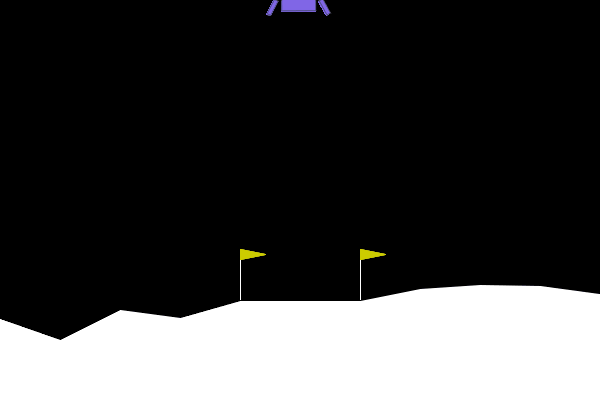

In [12]:
#Codigo hecho con claude
episodios = [500, 525, 550, 575]
entrenar_hasta(episodios)
ver_episodios(episodios)

Aquí podemos ver la primera mejora: la nave ya casi no gira y baja más derecha, usando el motor principal (se ven las partículas abajo). Todavía no le atina a la plataforma y se estrella a los lados de las banderas, pero la recompensa ya subió a entre −75 y −100.

### 12. Episodios 1,000, 1,025, 1,050 y 1,075
Seguimos hasta llegar al episodio 1,000.

Pasos de entrenamiento hasta ahora: 114,688
Episodio 1,000: recompensa = -79.0, pasos = 102
Episodio 1,025: recompensa = -73.5, pasos = 142
Episodio 1,050: recompensa = -59.2, pasos = 115
Episodio 1,075: recompensa = -86.2, pasos = 85



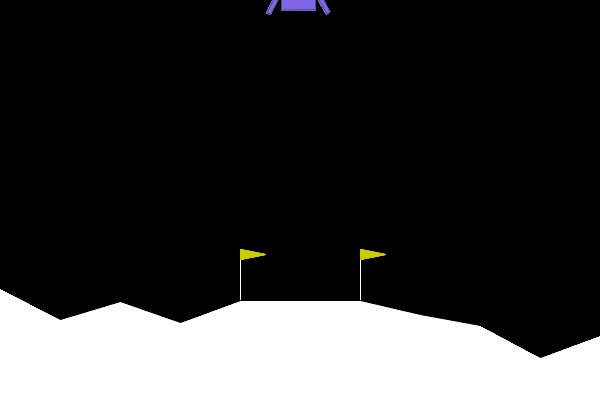

In [13]:
#Codigo hecho con claude
episodios = [1000, 1025, 1050, 1075]
entrenar_hasta(episodios)
ver_episodios(episodios)

Aquí podemos ver que a simple vista casi no cambió: sigue bajando más o menos derecha y se sigue estrellando a los lados de las banderas, a veces ladeada. La recompensa subió poquito (entre −59 y −86) y los episodios duran un poco más. O sea que no siempre se nota la mejora de un momento a otro, el agente va aprendiendo poco a poco.

### 13. Episodios 1,400, 1,425 y 1,450
Seguimos hasta el episodio 1,400. Estos ya duran un poco más, así que con 3 alcanza para los 8 segundos.

Pasos de entrenamiento hasta ahora: 163,840
Episodio 1,400: recompensa = 16.7, pasos = 129
Episodio 1,425: recompensa = 13.1, pasos = 107
Episodio 1,450: recompensa = 15.2, pasos = 159



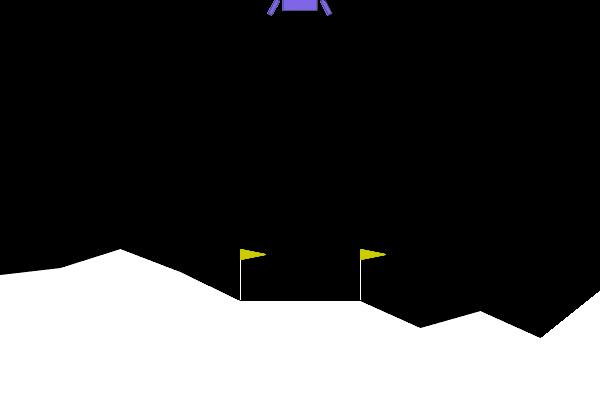

In [14]:
#Codigo hecho con claude
episodios = [1400, 1425, 1450]
entrenar_hasta(episodios)
ver_episodios(episodios)

Aquí podemos ver un cambio grande: **ya le atina a la plataforma**. En los 3 episodios llega derecha entre las banderas y la recompensa ya es positiva (de 13 a 17 puntos). Pero toca el suelo muy fuerte y cuenta como choque, así que todavía le quitan los 100 puntos.

### 14. Episodio 1,950
Seguimos hasta el episodio 1,950. Este episodio dura 20 segundos, así que el gif va acelerado para que dure 8.

Pasos de entrenamiento hasta ahora: 360,448
Episodio 1,950: recompensa = 169.5, pasos = 1000



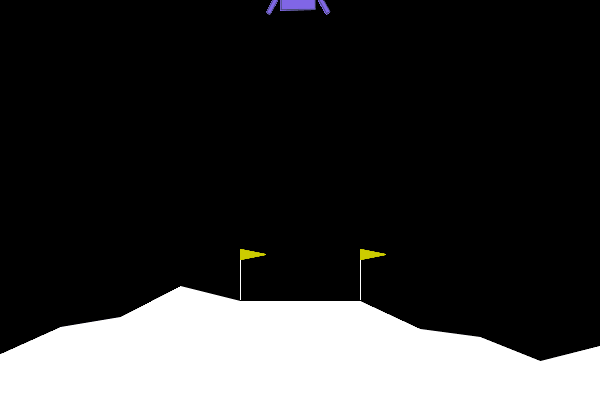

In [15]:
#Codigo hecho con claude
episodios = [1950]
entrenar_hasta(episodios)
ver_episodios(episodios)

Aquí podemos ver que ya no se estrella: baja, llega a la plataforma junto a la bandera izquierda y ahí se queda. Pero no termina de aterrizar, porque sigue prendiendo los motores a ratos (se ven las partículas). Como nunca se queda quieta no le dan los +100, y el episodio se corta a los 1,000 pasos. Aprendió a evitar el −100 de estrellarse, pero le da miedo aterrizar. Aun así saca 169.5 puntos, lo más alto hasta ahora.

### 15. Episodio 2,300
Seguimos hasta el episodio 2,300. También dura 20 segundos, así que va acelerado.

Pasos de entrenamiento hasta ahora: 638,976
Episodio 2,300: recompensa = 117.9, pasos = 1000



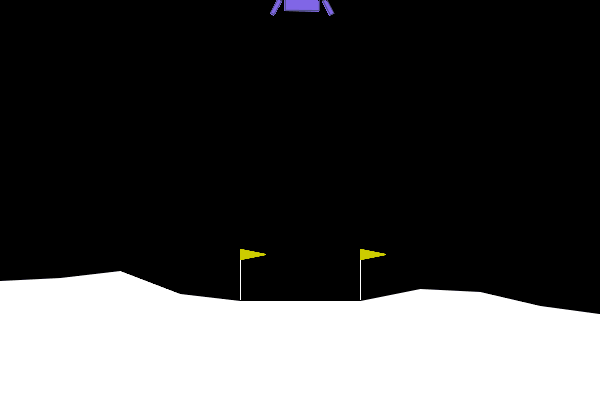

In [16]:
#Codigo hecho con claude
episodios = [2300]
entrenar_hasta(episodios)
ver_episodios(episodios)

Aquí podemos ver el mismo problema: llega junto a la bandera derecha, se queda ladeada en la orilla de la plataforma y sigue prendiendo motores hasta que se acaba el tiempo. Saca menos puntos que el episodio 1,950 (117.9) porque quedó ladeada y en la orilla, pero es la misma estrategia. Como no estrellarse ya le da puntos, el agente se queda un buen rato haciendo esto.

### 16. Episodio 2,575
Seguimos hasta el episodio 2,575. Dura casi 12 segundos, así que va un poco acelerado.

Pasos de entrenamiento hasta ahora: 884,736
Episodio 2,575: recompensa = 270.9, pasos = 583



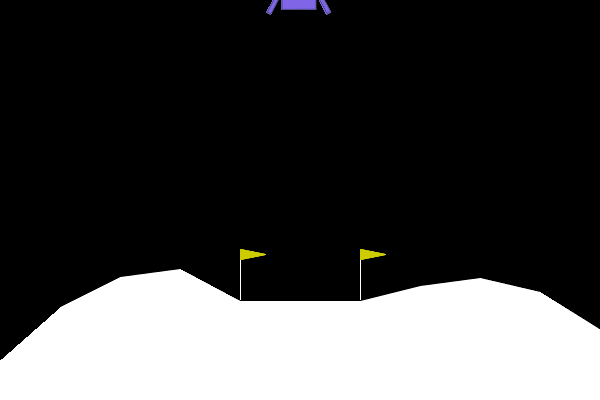

In [17]:
#Codigo hecho con claude
episodios = [2575]
entrenar_hasta(episodios)
ver_episodios(episodios)

Aquí podemos ver que **por fin aterriza**: baja entre las banderas, se queda derecha y esta vez sí se queda quieta, así que le dan los +100 y termina con 270.9 puntos. Todavía es lenta, porque se tarda 583 pasos (casi 12 segundos).

### 17. Episodio 2,825
Seguimos hasta el episodio 2,825, ya casi al final del entrenamiento.

Pasos de entrenamiento hasta ahora: 1,015,808
Episodio 2,825: recompensa = 298.0, pasos = 309



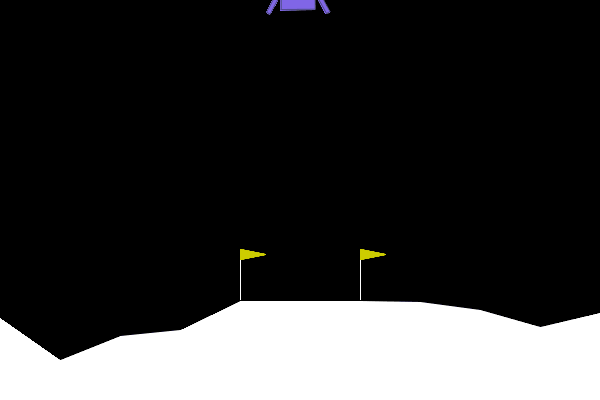

In [18]:
#Codigo hecho con claude
episodios = [2825]
entrenar_hasta(episodios)
ver_episodios(episodios)

Aquí podemos ver que ya aterriza bien y mucho más rápido: empieza ladeada, se endereza en el aire, baja frenando con el motor principal y se queda quieta entre las banderas. Se tarda 309 pasos (unos 6 segundos), casi la mitad que el episodio 2,575, y saca 298 puntos. Con este ya pasamos el millón de pasos, así que aquí se acaba el entrenamiento.

### 18. Historial del entrenamiento
Con el episodio 2,825 ya pasamos el millón de pasos, así que aquí termina el entrenamiento. Juntamos la recompensa y los pasos de todos los episodios en un DataFrame y los resumimos por bloques de 250 episodios.

In [19]:
#Codigo hecho con claude
envs.close()

print(f"Pasos de entrenamiento: {modelo.num_timesteps:,}")
print(f"Tiempo de entrenamiento: {tiempo_entrenando / 60:.1f} minutos")

historial = pd.DataFrame(registro['historial']).sort_values('episodio').reset_index(drop=True)
historial['exitoso'] = historial['recompensa'] >= 200
print(f"Episodios completos en el entrenamiento: {len(historial):,}\n")

# Resumen por bloques de 250 episodios
historial['bloque'] = (historial['episodio'] - 1) // 250
resumen = historial.groupby('bloque').agg(
    episodios=('episodio', lambda e: f"{e.min()}-{e.max()}"),
    recompensa_promedio=('recompensa', 'mean'),
    pasos_promedio=('pasos', 'mean'),
    exitosos=('exitoso', 'sum'))
resumen.round(1)

Pasos de entrenamiento: 1,015,808
Tiempo de entrenamiento: 5.3 minutos
Episodios completos en el entrenamiento: 2,857



,episodios,recompensa_promedio,pasos_promedio,exitosos
bloque,,,,
0,1-250,-176.6,91.5,0
1,251-500,-144.1,96.4,0
2,501-750,-116.8,97.3,0
3,751-1000,-87.3,101.5,0
4,1001-1250,-54.4,114.2,0
5,1251-1500,-25.2,151.8,0
6,1501-1750,-10.9,248.5,0
7,1751-2000,35.8,608.4,0
8,2001-2250,94.9,779.4,1


Aquí podemos ver que la recompensa va subiendo bloque por bloque, pero los primeros episodios exitosos aparecen hasta después del episodio 2,000, y casi todos en los últimos dos bloques.

### 19. Curva de aprendizaje
Graficamos la recompensa y los pasos de cada episodio con su promedio móvil de 50 episodios.

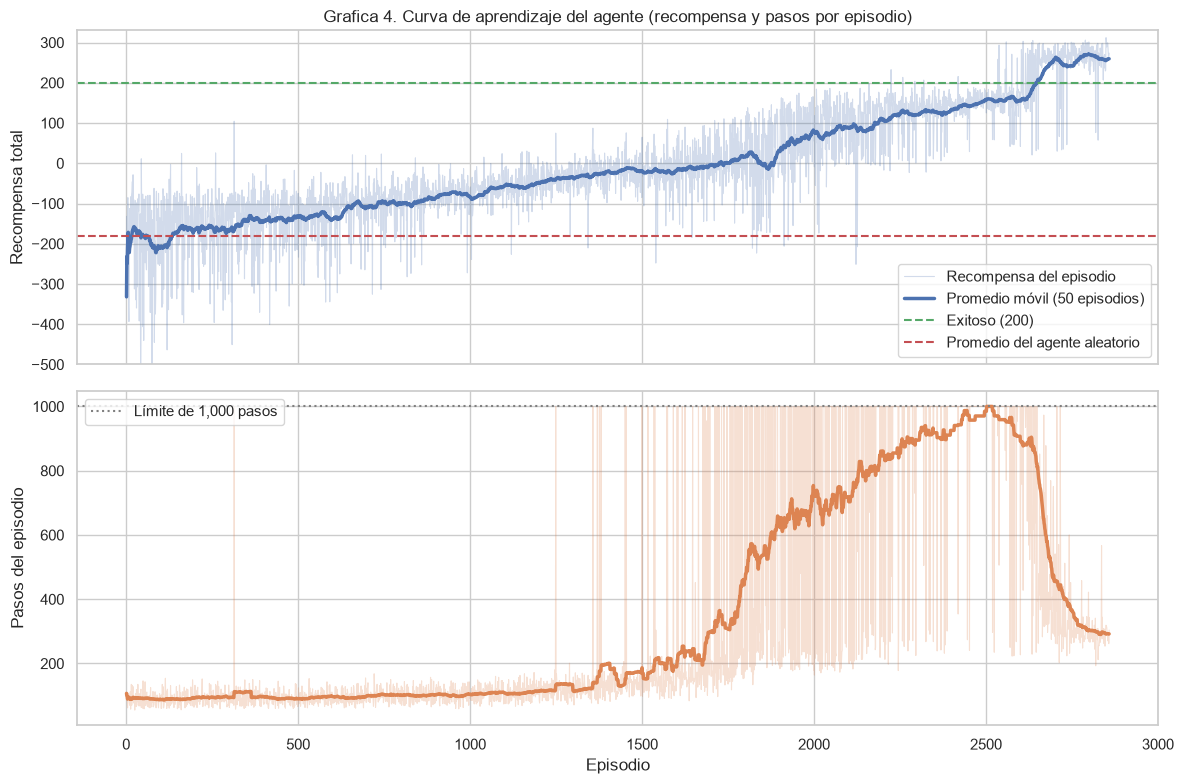

In [20]:
#Codigo hecho con claude
historial['promedio_movil'] = historial['recompensa'].rolling(50, min_periods=1).mean()
historial['pasos_movil'] = historial['pasos'].rolling(50, min_periods=1).mean()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
ax1.plot(historial['episodio'], historial['recompensa'], color='#4C72B0', alpha=0.25, lw=0.8, label='Recompensa del episodio')
ax1.plot(historial['episodio'], historial['promedio_movil'], color='#4C72B0', lw=2.5, label='Promedio móvil (50 episodios)')
ax1.axhline(200, color='#55A868', ls='--', lw=1.5, label='Exitoso (200)')
ax1.axhline(recompensas_aleatorias.mean(), color='#C44E52', ls='--', lw=1.5, label='Promedio del agente aleatorio')
ax1.set_ylabel('Recompensa total')
ax1.set_ylim(-500, 330)
ax1.legend(loc='lower right')
ax1.set_title('Grafica 4. Curva de aprendizaje del agente (recompensa y pasos por episodio)')

ax2.plot(historial['episodio'], historial['pasos'], color='#DD8452', alpha=0.25, lw=0.8)
ax2.plot(historial['episodio'], historial['pasos_movil'], color='#DD8452', lw=2.5)
ax2.axhline(1000, color='gray', ls=':', lw=1.5, label='Límite de 1,000 pasos')
ax2.set_xlabel('Episodio')
ax2.set_ylabel('Pasos del episodio')
ax2.legend(loc='upper left')
plt.tight_layout()
plt.show()

Aquí podemos ver 4 etapas, las mismas que fuimos viendo en los gifs:

1. **Se estrella** (1 a ~1,000): episodios de unos 100 pasos, pero cada vez baja más derecha y la recompensa va subiendo.
2. **Baja con más control** (~1,000 a ~1,700): la recompensa llega casi a 0 y ya le atina a la plataforma, pero todavía choca al tocar el suelo.
3. **Le da miedo aterrizar** (~1,700 a ~2,600): los pasos suben hasta 1,000 porque llega a las banderas pero sigue prendiendo los motores a ratos, y se le acaba el tiempo sin recibir el +100.
4. **Aterriza** (~2,600 en adelante): la recompensa pasa los 200 y los episodios bajan a unos 300 pasos.

### 20. Evaluación del agente entrenado
Jugamos 100 episodios nuevos con `deterministic=True` (siempre la mejor acción) y lo comparamos contra el agente aleatorio.

In [21]:
#Codigo hecho con claude
env_eval = gym.make('LunarLander-v3')
recompensas_entrenado, pasos_entrenado = [], []

for i in range(100):
    observation, info = env_eval.reset(seed=10_000 + i)
    done, total_reward, pasos = False, 0.0, 0
    while not done:
        action, _ = modelo.predict(observation, deterministic=True)
        observation, reward, terminated, truncated, info = env_eval.step(action)
        total_reward += reward
        pasos += 1
        done = terminated or truncated
    recompensas_entrenado.append(total_reward)
    pasos_entrenado.append(pasos)

env_eval.close()
recompensas_entrenado = np.array(recompensas_entrenado)

comparacion = pd.DataFrame({
    'Agente aleatorio': [recompensas_aleatorias.mean(), np.median(recompensas_aleatorias),
                         recompensas_aleatorias.min(), (recompensas_aleatorias >= 200).mean() * 100],
    'Agente entrenado': [recompensas_entrenado.mean(), np.median(recompensas_entrenado),
                         recompensas_entrenado.min(), (recompensas_entrenado >= 200).mean() * 100]},
    index=['Recompensa promedio', 'Recompensa mediana', 'Recompensa mínima', '% de episodios exitosos'])
print(f"Pasos promedio del agente entrenado: {np.mean(pasos_entrenado):.0f}")
comparacion.round(1)

Pasos promedio del agente entrenado: 323


,Agente aleatorio,Agente entrenado
Recompensa promedio,-181.2,260.4
Recompensa mediana,-148.3,260.7
Recompensa mínima,-587.0,69.2
% de episodios exitosos,0.0,99.0


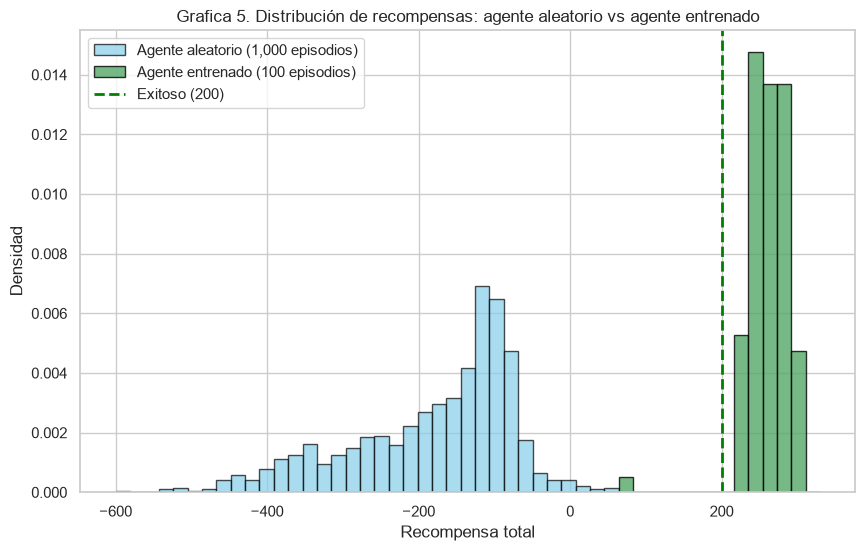

In [22]:
plt.figure(figsize=(10, 6))
bins = np.linspace(-600, 330, 50)
plt.hist(recompensas_aleatorias, bins=bins, color='skyblue', edgecolor='black', alpha=0.7, density=True, label='Agente aleatorio (1,000 episodios)')
plt.hist(recompensas_entrenado, bins=bins, color='#55A868', edgecolor='black', alpha=0.8, density=True, label='Agente entrenado (100 episodios)')
plt.axvline(200, color='green', linestyle='dashed', linewidth=2, label='Exitoso (200)')
plt.title("Grafica 5. Distribución de recompensas: agente aleatorio vs agente entrenado")
plt.xlabel("Recompensa total")
plt.ylabel("Densidad")
plt.legend()
plt.show()

Aquí podemos ver que el agente entrenado saca 260 puntos en promedio contra −181 del aleatorio, y aterrizó bien en 99 de los 100 episodios.

### 21. Agente entrenado
Jugamos un episodio usando siempre la mejor acción, y hacemos su gif.

Evaluación terminada con una recompensa de 253.47 en 312 pasos
Recompensa del último paso: 100



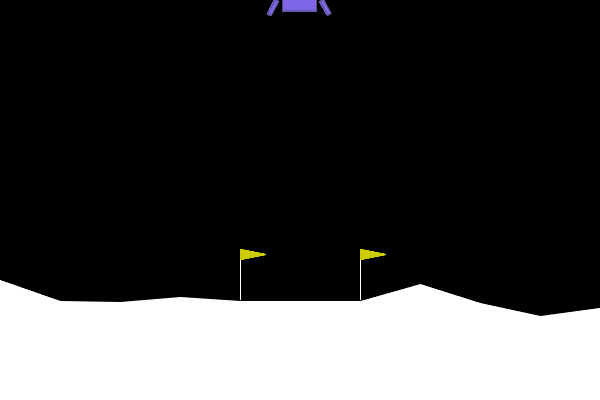

In [23]:
eval_env = gym.make('LunarLander-v3', render_mode='rgb_array')
observation, info = eval_env.reset(seed=10_000)

eval_frames = [a_cuadro(eval_env.render())]
total_eval_reward, pasos, done = 0.0, 0, False

while not done:
    # Selección determinista de la mejor acción aprendida
    action, _ = modelo.predict(observation, deterministic=True)
    observation, reward, terminated, truncated, info = eval_env.step(action)
    total_eval_reward += reward
    pasos += 1
    done = terminated or truncated
    if pasos % 2 == 0 or done:
        eval_frames.append(a_cuadro(eval_env.render()))

eval_env.close()
print(f"Evaluación terminada con una recompensa de {total_eval_reward:.2f} en {pasos} pasos")
print(f"Recompensa del último paso: {reward:.0f}")
mostrar_gif(eval_frames)

Aquí podemos ver al agente ya terminado, sin nada de azar en sus acciones: baja frenando con el motor principal, se mantiene derecha, aterriza entre las banderas y se queda quieta. Saca 253.47 puntos en 312 pasos, y el último paso le da el +100 de aterrizar.

# Conclusión

El agente pasó de estrellarse como el agente aleatorio (−181 puntos en promedio) a aterrizar bien en 99 de 100 episodios (260 puntos), solo con prueba y error y la recompensa de cada paso. En los gifs se ve que no aprendió todo de golpe, sino por partes: primero a no dar vueltas, luego a atinarle a la plataforma, luego a no estrellarse, y hasta el final a quedarse quieta.

Lo más interesante fue la etapa de los episodios 1,950 y 2,300: aprendió a evitar el castigo de estrellarse antes de descubrir el premio de aterrizar, y le tomó cientos de episodios salir de ahí. El agente no sabe que el objetivo es aterrizar, solo busca más recompensa, así que se queda con lo que le funciona hasta que, explorando, encuentra algo mejor. Por eso en aprendizaje por refuerzo importa tanto cómo se define la recompensa y que el agente siga explorando.

También se ve la diferencia con Q-learning: con PPO no hubo que partir las 8 variables en rangos, porque la red neuronal las recibe tal cual. Eso sí, ocupa muchísimos intentos: los primeros episodios exitosos aparecieron hasta después del episodio 2,000, de 2,857 en total. Aun así, con 16 ambientes en paralelo el entrenamiento tardó unos 5 minutos.